# Tugas Deteksi Objek YOLO Pretrained (Google Colab)

Notebook siap pakai untuk:
1. Menjalankan **YOLO pretrained** (YOLOv8n, COCO 80 kelas).
2. Menguji pada **6 gambar berbeda**.
3. Menyimpan **gambar asli + hasil deteksi**.
4. Mencatat **label, confidence, bounding box**.
5. Membandingkan hasil pada **dua confidence threshold** (0.25 vs 0.50).
6. Menyimpan hasil ke **database (SQLite)**.

**Cara pakai:** `Runtime` -> `Change runtime type` -> pilih **GPU** (opsional, CPU juga jalan).
Lalu jalankan semua sel dari atas ke bawah (`Runtime` -> `Run all`).


## 1. Setup environment

In [ ]:
# Cek GPU & install Ultralytics
import torch
print("Torch :", torch.__version__)
print("GPU   :", torch.cuda.is_available())
if torch.cuda.is_available():
    print("Device:", torch.cuda.get_device_name(0))

!pip -q install ultralytics

Torch : 2.11.0+cpu
GPU   : False


## 2. Siapkan 6 gambar uji (otomatis)

In [ ]:
from pathlib import Path
import urllib.request

IMAGE_DIR = Path("images")
IMAGE_DIR.mkdir(exist_ok=True)

SOURCES = {
    "01_bus.jpg": ["https://ultralytics.com/images/bus.jpg"],
    "02_zidane.jpg": ["https://ultralytics.com/images/zidane.jpg"],
    "03_dog1.jpg": ["https://raw.githubusercontent.com/pytorch/vision/main/gallery/assets/dog1.jpg"],
    "04_dog2.jpg": ["https://raw.githubusercontent.com/pytorch/vision/main/gallery/assets/dog2.jpg"],
    "05_basketball.png": ["https://raw.githubusercontent.com/opencv/opencv/4.x/samples/data/basketball1.png"],
    "06_board.jpg": ["https://raw.githubusercontent.com/opencv/opencv/4.x/samples/data/board.jpg"],
}

for name, urls in SOURCES.items():
    dest = IMAGE_DIR / name
    if dest.exists() and dest.stat().st_size > 1024:
        print("[skip]", name)
        continue
    for url in urls:
        try:
            req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
            dest.write_bytes(urllib.request.urlopen(req, timeout=60).read())
            print("[ok]  ", name)
            break
        except Exception as e:
            print("[gagal]", url, e)

imgs = sorted(p for p in IMAGE_DIR.iterdir() if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".webp", ".bmp"})
print("\nTotal gambar:", len(imgs))

[ok]   01_bus.jpg
[ok]   02_zidane.jpg
[ok]   03_dog1.jpg
[ok]   04_dog2.jpg
[ok]   05_basketball.png
[ok]   06_board.jpg

Total gambar: 6


## 2b. (OPSIONAL) Upload gambar sendiri

Lewati sel ini kalau cukup memakai 6 gambar contoh di atas.


In [ ]:
# OPSIONAL: upload gambar sendiri dari komputer
try:
    from google.colab import files
    uploaded = files.upload()
    for name, data in uploaded.items():
        Path("images", name).write_bytes(data)
        print("tersimpan:", name)
except Exception as e:
    print("Dilewati:", e)

## 3. Jalankan YOLO + simpan gambar hasil deteksi

In [ ]:
from IPython.display import display
from ultralytics import YOLO
import cv2
import pandas as pd
from pathlib import Path

CONFS = [0.25, 0.50]
OUT_DIR = Path("hasil")
OUT_DIR.mkdir(exist_ok=True)

model = YOLO("yolov8n.pt")

images = sorted(p for p in Path("images").iterdir()
                if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".webp", ".bmp"})

rows = []
for img in images:
    frame = cv2.imread(str(img))
    h, w = frame.shape[:2]
    for conf in CONFS:
        result = model.predict(source=str(img), conf=conf, verbose=False)[0]
        annotated = result.plot()
        out_file = OUT_DIR / f"{img.stem}__conf{conf:.2f}.jpg"
        cv2.imwrite(str(out_file), annotated)

        boxes = result.boxes
        n = 0
        if boxes is not None and len(boxes) > 0:
            for box in boxes:
                x1, y1, x2, y2 = (round(float(v), 1) for v in box.xyxy[0].tolist())
                rows.append({
                    "image": img.name,
                    "threshold": conf,
                    "label": result.names[int(box.cls[0])],
                    "confidence": round(float(box.conf[0]), 4),
                    "x1": x1, "y1": y1, "x2": x2, "y2": y2,
                    "width": round(x2 - x1, 1),
                    "height": round(y2 - y1, 1),
                })
                n += 1
        print(f"{img.name:<20} conf {conf:<5} -> {n} objek")

df = pd.DataFrame(rows)
df.to_csv(OUT_DIR / "detections.csv", index=False)
print("\nTotal deteksi:", len(df), "| CSV: hasil/detections.csv")
display(df)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
01_bus.jpg           conf 0.25  -> 6 objek
01_bus.jpg           conf 0.5   -> 4 objek
02_zidane.jpg        conf 0.25  -> 3 objek
02_zidane.jpg        conf 0.5   -> 2 objek
03_dog1.jpg          conf 0.25  -> 1 objek
03_dog1.jpg          conf 0.5   -> 1 objek
04_dog2.jpg          conf 0.25  -> 1 objek
04_dog2.jpg          conf 0.5   -> 1 objek
05_basketball.png    conf 0.25  -> 2 objek
05_basketball.png    conf 0.5   -> 2 objek
06_board.jpg         conf 0.25  -> 5 objek
06_board.jpg         conf 0.5   -> 2 objek

Total deteksi: 30 | CSV: hasil/detections.csv


,image,threshold,label,confidence,x1,y1,x2,y2,width,height
0,01_bus.jpg,0.25,bus,0.8734,22.9,231.3,805.0,756.8,782.1,525.5
1,01_bus.jpg,0.25,person,0.8657,48.6,398.6,245.3,902.7,196.7,504.1
2,01_bus.jpg,0.25,person,0.8528,669.5,392.2,809.7,877.0,140.2,484.8
3,01_bus.jpg,0.25,person,0.8252,221.5,405.8,345.0,857.5,123.5,451.7
4,01_bus.jpg,0.25,person,0.2611,0.0,550.5,63.0,873.4,63.0,322.9
5,01_bus.jpg,0.25,stop sign,0.2551,0.1,254.5,32.6,324.9,32.5,70.4
6,01_bus.jpg,0.50,bus,0.8734,22.9,231.3,805.0,756.8,782.1,525.5
7,01_bus.jpg,0.50,person,0.8657,48.6,398.6,245.3,902.7,196.7,504.1
8,01_bus.jpg,0.50,person,0.8528,669.5,392.2,809.7,877.0,140.2,484.8
9,01_bus.jpg,0.50,person,0.8252,221.5,405.8,345.0,857.5,123.5,451.7


## 4. Tampilkan gambar asli vs hasil deteksi


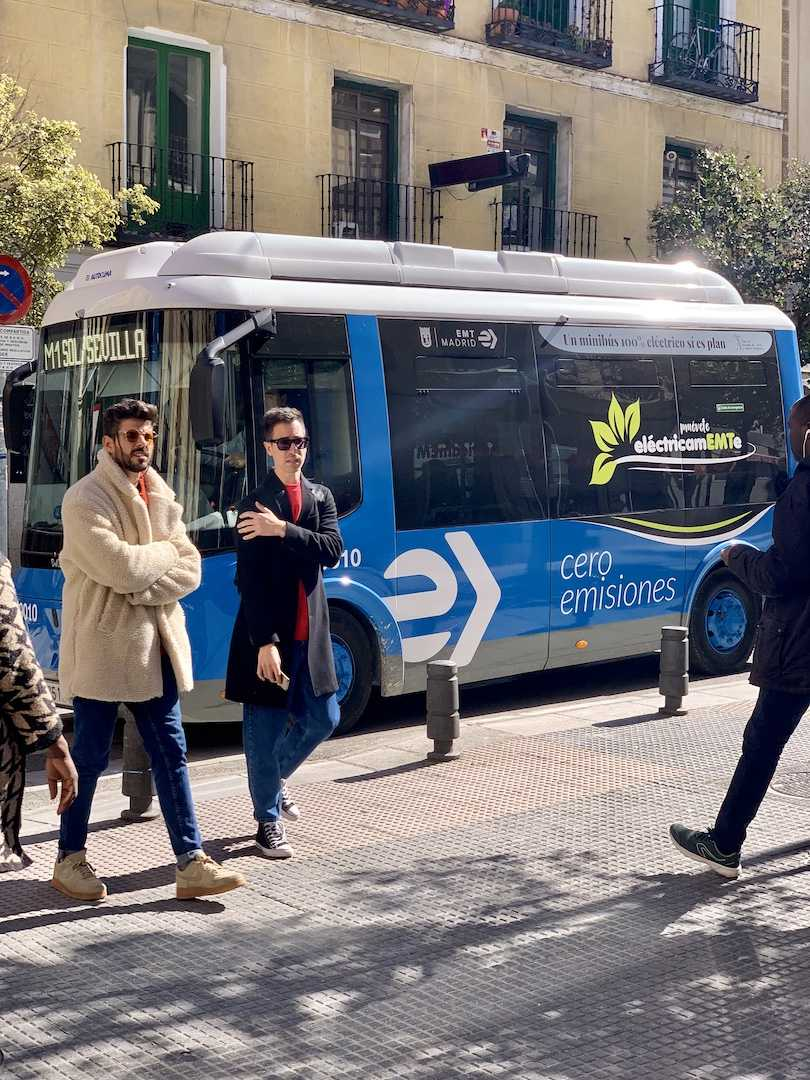
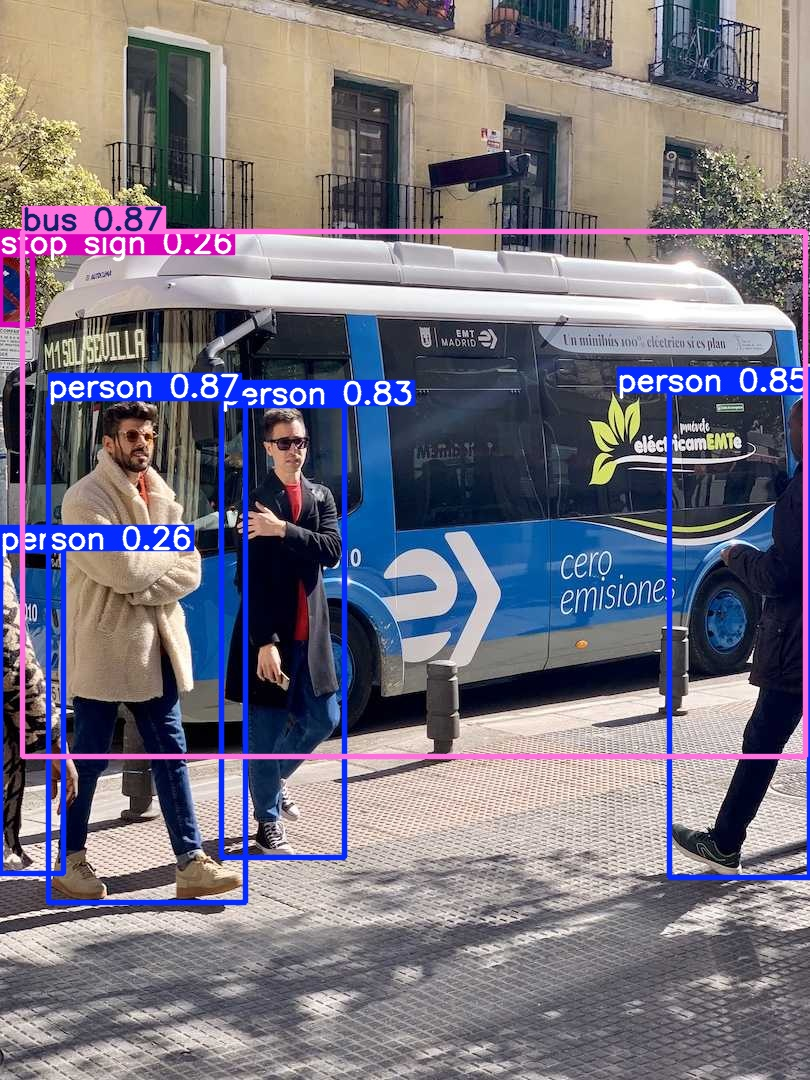
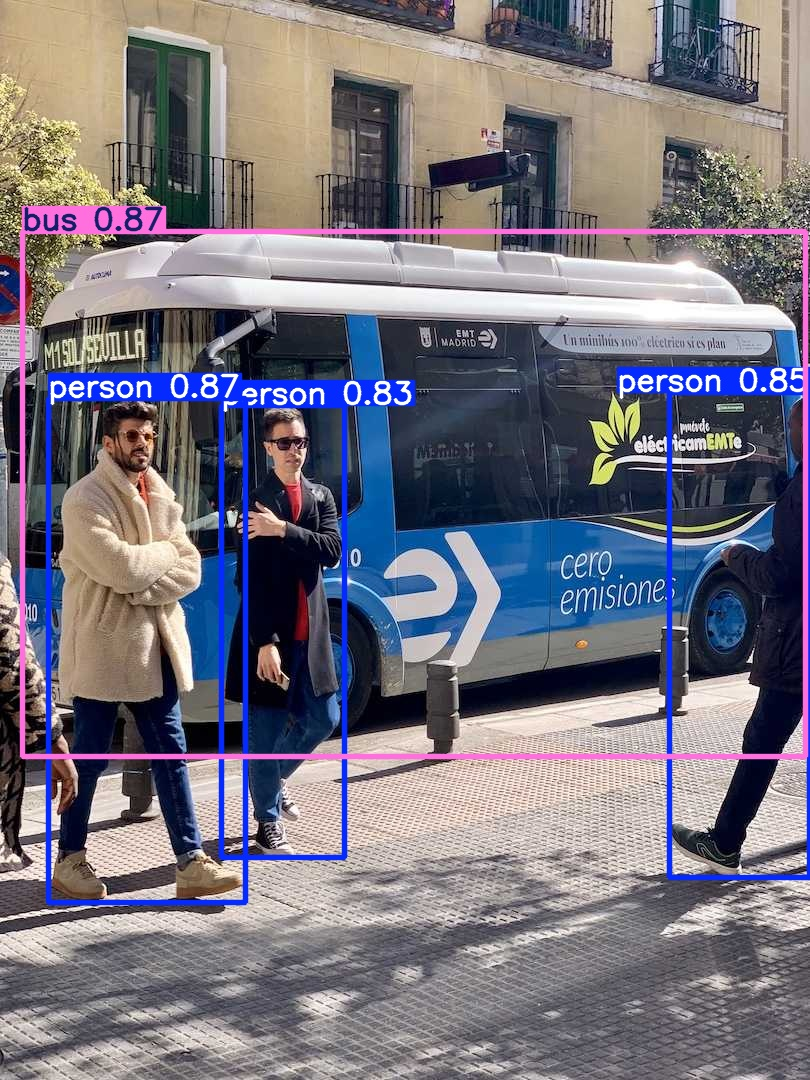


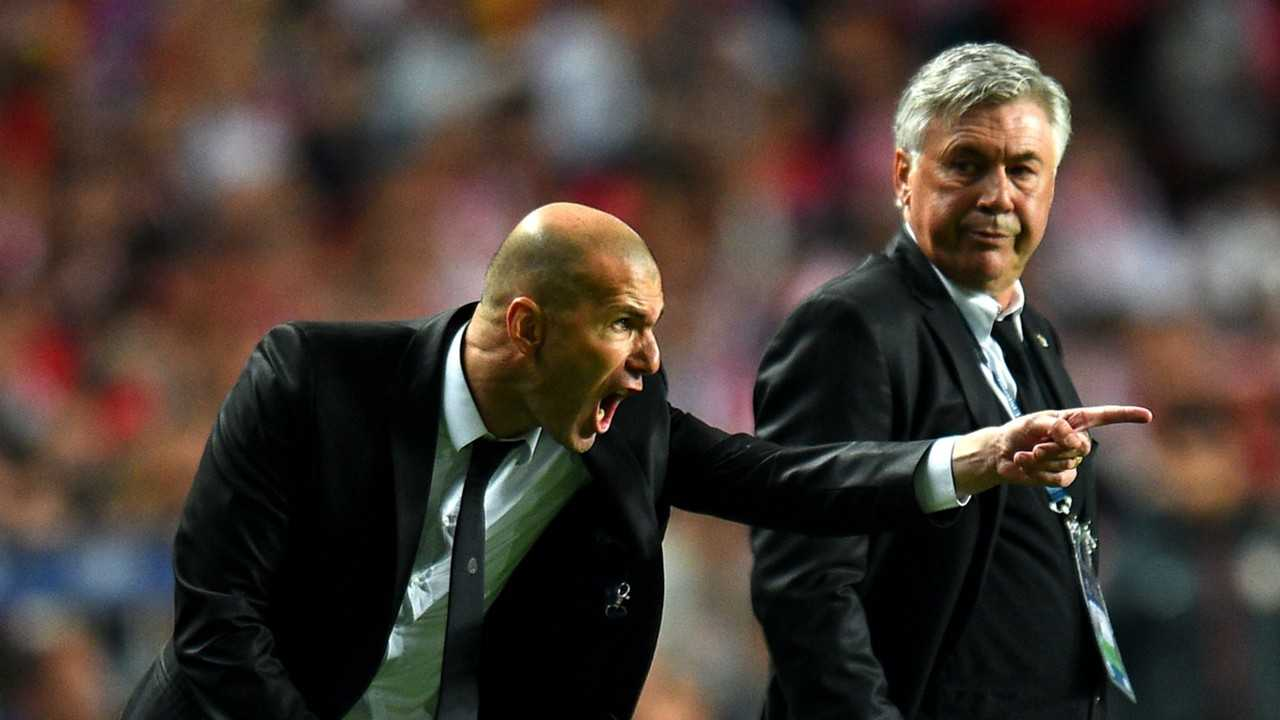
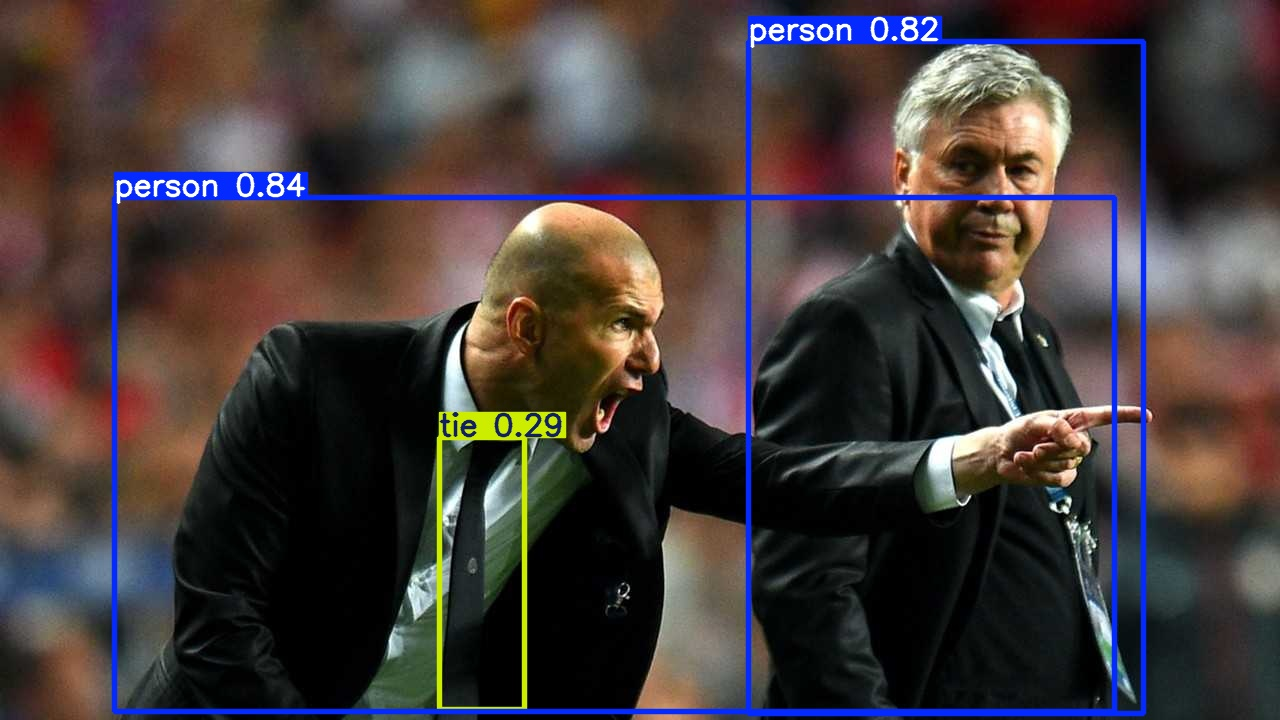
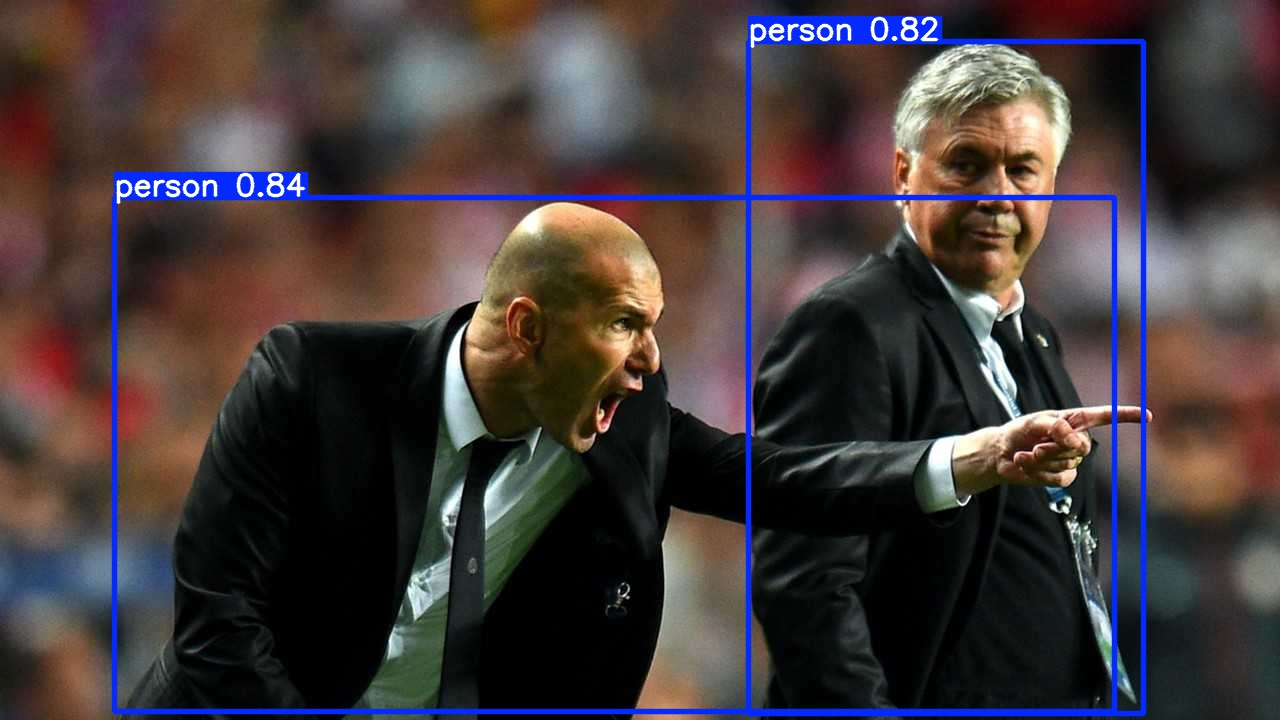


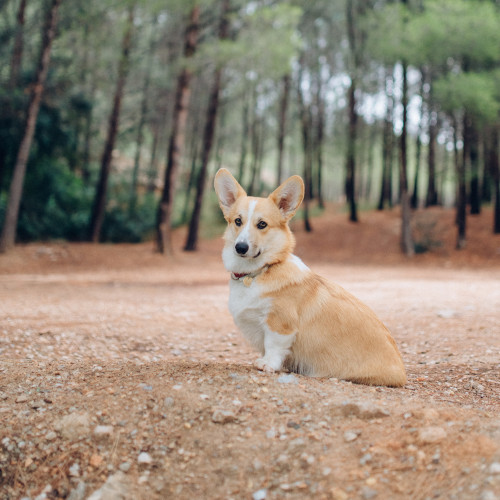
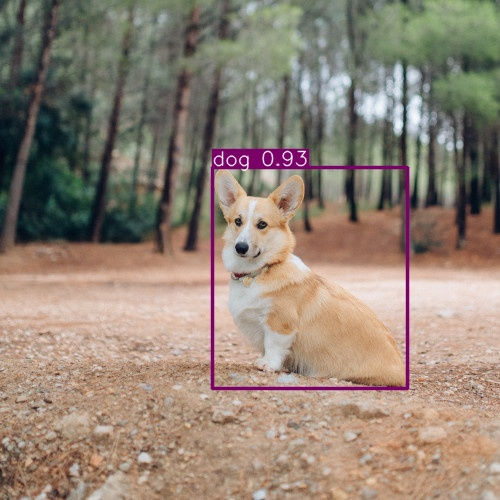
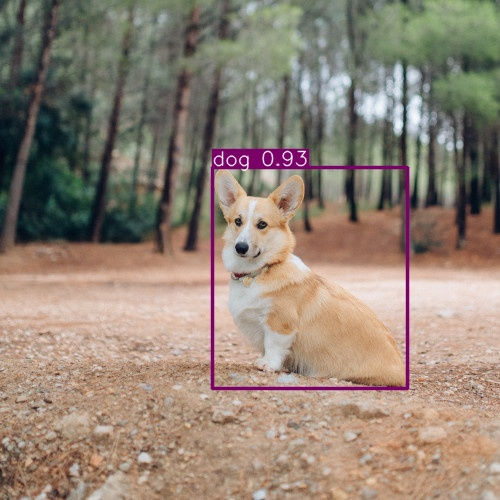


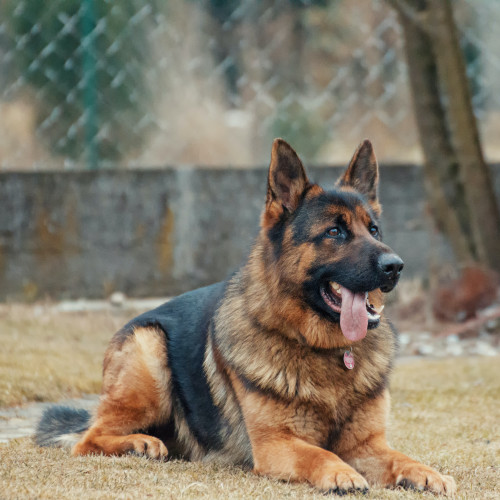
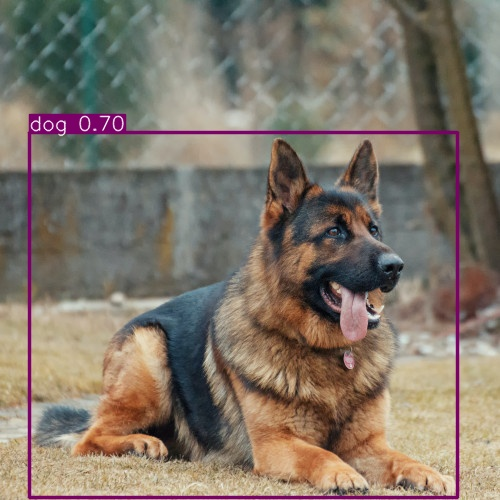
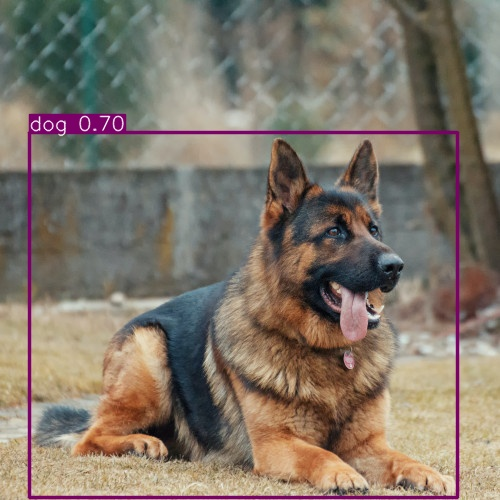


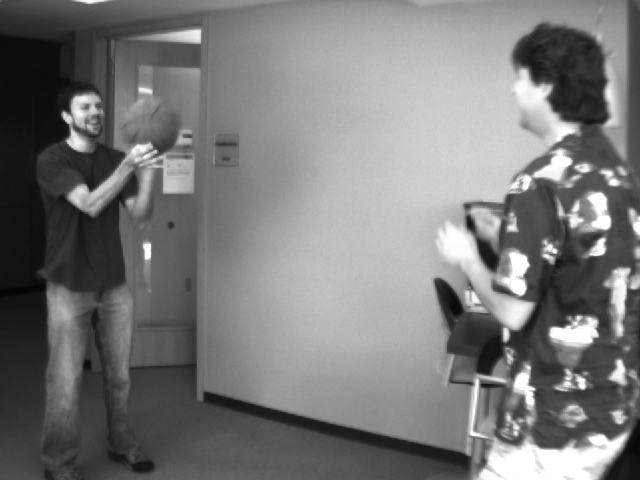
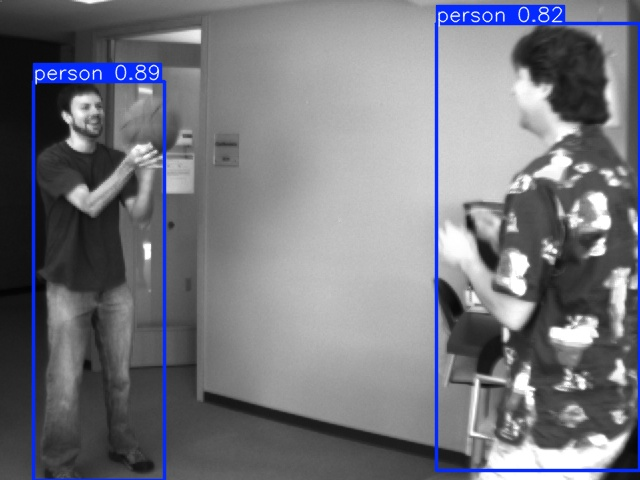
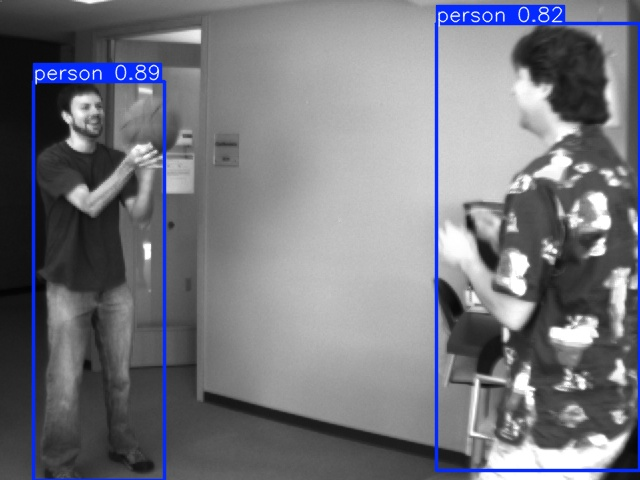


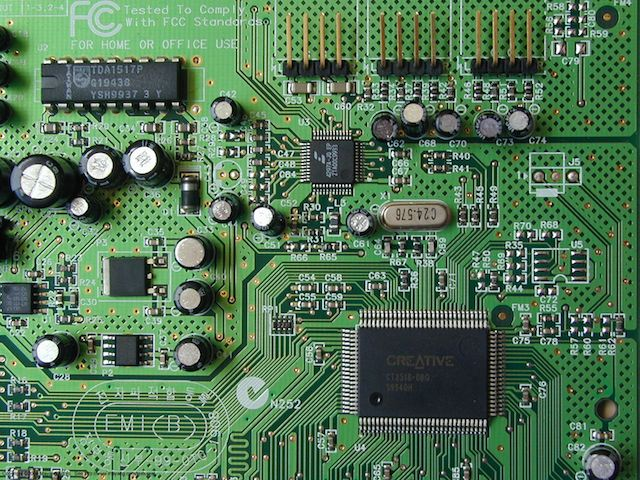
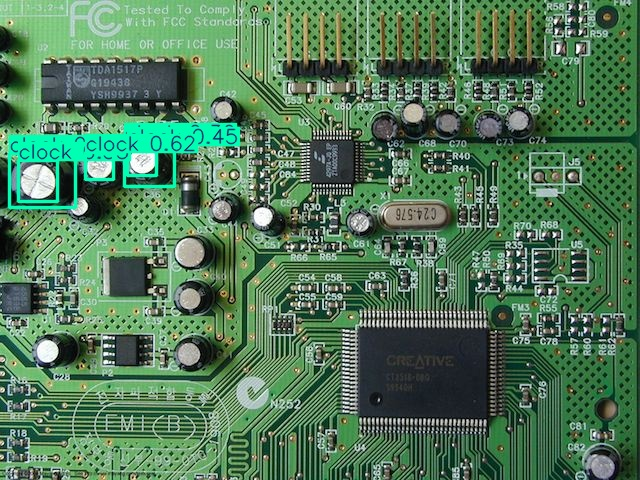
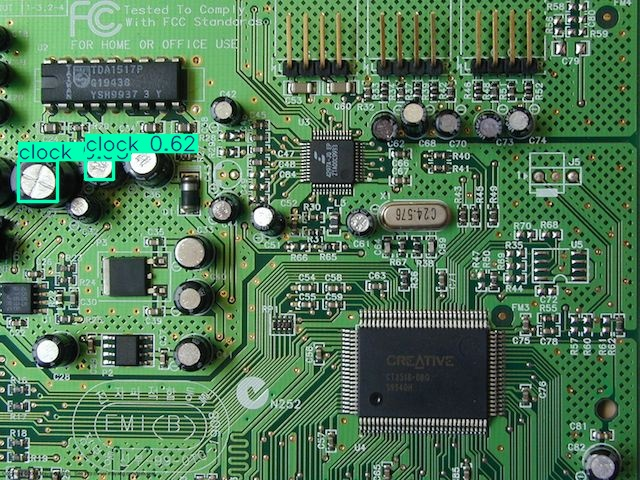

In [ ]:
from IPython.display import display, HTML
from pathlib import Path
import base64

def b64(path):
    return base64.b64encode(Path(path).read_bytes()).decode()

for img in images:
    files_html = f'<figure style="margin:0;text-align:center"><img src="data:image/jpeg;base64,{b64(img)}" style="width:100%;border-radius:8px"><figcaption style="font-size:12px;color:#666">Asli: {img.name}</figcaption></figure>'
    for conf in CONFS:
        det = OUT_DIR / f"{img.stem}__conf{conf:.2f}.jpg"
        files_html += f'<figure style="margin:0;text-align:center"><img src="data:image/jpeg;base64,{b64(det)}" style="width:100%;border-radius:8px"><figcaption style="font-size:12px;color:#666">Deteksi conf {conf}</figcaption></figure>'
    display(HTML(f'<div style="display:grid;grid-template-columns:repeat(3,1fr);gap:8px;margin-bottom:22px">{files_html}</div>'))

## 5. Bandingkan dua confidence threshold

In [ ]:
from IPython.display import display
low, high = min(CONFS), max(CONFS)

pivot = (df.groupby(["image", "threshold"])
           .size().unstack(fill_value=0)
           .reindex(columns=CONFS, fill_value=0))
pivot["selisih"] = pivot[low] - pivot[high]
pivot = pivot.reset_index()
print(f"Total deteksi @ {low}: {pivot[low].sum()}")
print(f"Total deteksi @ {high}: {pivot[high].sum()}")
print(f"Selisih                : {pivot['selisih'].sum()}\n")
display(pivot)

print("\nObjek yang hilang saat threshold dinaikkan:")
for _, r in pivot.iterrows():
    if r["selisih"] > 0:
        print(f"  - {r['image']}: {r['selisih']} deteksi")

## 6. Simpan hasil ke database (SQLite)

Di Colab tidak ada Docker MariaDB, jadi dipakai **SQLite** (`yolo_detection.db`).
Strukturnya sama: tabel `images`, `detections`, plus view ringkasan.


In [ ]:
from IPython.display import display
import sqlite3
import pandas as pd

conn = sqlite3.connect("yolo_detection.db")
cur = conn.cursor()

cur.executescript('''
CREATE TABLE IF NOT EXISTS images (
    id INTEGER PRIMARY KEY AUTOINCREMENT,
    filename TEXT UNIQUE NOT NULL,
    width INTEGER,
    height INTEGER
);
CREATE TABLE IF NOT EXISTS detections (
    id INTEGER PRIMARY KEY AUTOINCREMENT,
    image_id INTEGER NOT NULL,
    threshold REAL NOT NULL,
    label TEXT NOT NULL,
    confidence REAL NOT NULL,
    x1 REAL, y1 REAL, x2 REAL, y2 REAL,
    width REAL, height REAL,
    FOREIGN KEY (image_id) REFERENCES images(id)
);
DELETE FROM detections;
DELETE FROM images;
''')

for img in images:
    frame = cv2.imread(str(img))
    h, w = frame.shape[:2]
    cur.execute("INSERT OR IGNORE INTO images (filename, width, height) VALUES (?,?,?)", (img.name, w, h))
conn.commit()

img_ids = {r[1]: r[0] for r in cur.execute("SELECT id, filename FROM images").fetchall()}
for _, r in df.iterrows():
    cur.execute('''INSERT INTO detections
        (image_id, threshold, label, confidence, x1, y1, x2, y2, width, height)
        VALUES (?,?,?,?,?,?,?,?,?,?)''',
        (img_ids[r["image"]], float(r["threshold"]), r["label"], float(r["confidence"]),
         float(r["x1"]), float(r["y1"]), float(r["x2"]), float(r["y2"]),
         float(r["width"]), float(r["height"])))
conn.commit()

print("Tersimpan:", cur.execute("SELECT COUNT(*) FROM detections").fetchone()[0], "deteksi")
print()
display(pd.read_sql_query('''
    SELECT i.filename, d.threshold, COUNT(*) AS jumlah_objek
    FROM detections d JOIN images i ON i.id = d.image_id
    GROUP BY i.filename, d.threshold
    ORDER BY i.filename, d.threshold
''', conn))
conn.close()

## 7. Unduh semua hasil (gambar + CSV + database)

In [ ]:
!zip -qr hasil_deteksi.zip images hasil yolo_detection.db

from google.colab import files
files.download("hasil_deteksi.zip")

## 8. (OPSIONAL) Versi web app di Colab

Web app Flask di project asli bisa dijalankan di Colab, tetapi Colab tidak
menyediakan port publik. Solusinya pakai tunnel gratis (cloudflared):

```python
!pip -q install flask
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O /usr/local/bin/cloudflared
!chmod +x /usr/local/bin/cloudflared

# jalankan app.py (dari project) di background, lalu:
!cloudflared tunnel --url http://127.0.0.1:5000
```

Cara paling praktis: jalankan web app di laptop (`./jalankan_web.sh`), dan pakai
notebook ini di Colab khusus untuk eksperimen/batch dengan GPU.
